# Project WikiPulse: Real-Time & Historical Analysis of Wikipedia Knowledge Shifts
## Spark DataFrame Analytics & Visual Exploration (enwiki Stream: Sept 16, 2026)

---

### Project Objective
Wikipedia is a dynamic, living knowledge repository reflecting real-time global events, social debates, and collaborative consensus. However, raw edit feeds are noisy: bots make tens of thousands of automated syntax updates, single editors rewrite minor articles, and breaking controversies trigger intense edit wars.

**WikiPulse** processes the high-throughput Wikimedia event stream at scale using **Apache Spark**. This notebook performs an end-to-end analytical study on the full **September 16, 2026** recent changes dataset (`rc_2026-09-16.jsonl.gz`) to answer core research questions:
1. **Volume & Rhythm**: How does edit velocity fluctuate across the 24 hours of UTC time?
2. **Editor Demographics**: What proportion of changes are driven by automated bots, registered humans, or anonymous/temporary accounts?
3. **Attention Hotspots**: Which mainspace articles attract the highest edit velocity and broad community participation?
4. **Controversy & Edit Wars**: How do we algorithmically detect edit warring using reverts, editor diversity, and byte volatility?
5. **Editorial Tooling**: Which editing interfaces (Mobile, VisualEditor, AutoWikiBrowser scripts) dominate contributions?

### Environment Initialization & Configuration
- Sets `JAVA_HOME` dynamically to Apple Silicon OpenJDK 17 (`/opt/homebrew/opt/openjdk@17`).
- Configures Spark with `spark.sql.session.timeZone = UTC` for timestamp consistency.
- Configures `spark.sql.caseSensitive = true` to handle MediaWiki's log parameters (which contain both `revid` and `revId` across different log actions).
- Uses Apache Arrow acceleration for fast PySpark-to-Pandas zero-copy visual conversions.

In [1]:
import os
import warnings

# Suppress conversion and deprecation notices
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Ensure Apple Silicon OpenJDK 17 is loaded
if "JAVA_HOME" not in os.environ or not os.path.exists(os.path.join(os.environ.get("JAVA_HOME", ""), "bin", "java")):
    if os.path.exists("/opt/homebrew/opt/openjdk@17"):
        os.environ["JAVA_HOME"] = "/opt/homebrew/opt/openjdk@17"
        os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ.get("PATH", "")

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession, functions as F, Window

# Modern aesthetic plotting configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.titlesize"] = 14
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["lines.linewidth"] = 2

# Initialize SparkSession
spark = (SparkSession.builder.appName("WikiPulse-Visual-Analysis")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.caseSensitive", "true")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print(f"✓ Spark Session Active: Version {spark.version}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/15 20:41:04 WARN Utils: Your hostname, Senthils-MacBook.local, resolves to a loopback address: 127.0.0.1; using 192.168.29.3 instead (on interface en0)
26/10/15 20:41:04 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/15 20:41:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


✓ Spark Session Active: Version 4.2.0


---
## Section 1: Ingestion & Feature Engineering

### Data Schema & Pipeline Transformations
We read `historical/data/enwiki_recentchanges/rc_2026-09-16.jsonl.gz`. Each record contains raw MediaWiki event data:
- `type`: Event classification (`edit`, `new`, `log`, `categorize`).
- `ns`: Namespace (`0` = encyclopedia articles; `1` = talk; `2` = user pages; `4` = project guidelines).
- `delta`: Computed as `newlen - oldlen` (net byte shift per revision).
- `is_revert`: Flag identifying revisions tagged with `mw-reverted`, `mw-manual-revert`, `mw-rollback`, or `mw-undo`.
- `is_anon`: Identified using Wikipedia's modern temporary IP mask accounts (`~2026-xxxxx-xx` with `temp: True`) or missing `userid`.

In [2]:
raw_path = "data/enwiki_recentchanges/rc_2026-09-16.jsonl.gz"

rc = (spark.read.json(raw_path)
      .withColumn("ts", F.to_timestamp("timestamp"))
      .withColumn("hour", F.date_trunc("hour", "ts"))
      .withColumn("delta", F.col("newlen") - F.col("oldlen"))
      .withColumn("is_revert", F.array_contains("tags", "mw-reverted")
                  | F.array_contains("tags", "mw-manual-revert")
                  | F.array_contains("tags", "mw-rollback")
                  | F.array_contains("tags", "mw-undo"))
      .withColumn("is_anon", (F.coalesce(F.col("temp"), F.lit(False)) == True) 
                             | F.col("user").startswith("~") 
                             | F.col("userid").isNull() 
                             | (F.col("userid") == 0))
      .withColumn("is_anon", F.coalesce(F.col("is_anon"), F.lit(False)))
      .cache())

total_changes = rc.count()
print(f"Ingested {total_changes:,} raw Wikipedia changes for Sept 16, 2026.")

Ingested 293,627 raw Wikipedia changes for Sept 16, 2026.


---
## Section 2: Global Event Distribution & Editor Class Breakdown

### Theoretical Context
Not every record in the recent changes stream is an encyclopedic edit:
- **`categorize`**: Automated bot tracking of page category indexing.
- **`log`**: Administrative operations (user creation, page moves, blocks, deletions).
- **`edit` & `new`**: Modifications to actual article text and page creations.

Within the **main encyclopedia namespace (`ns = 0`)**, we segment contributors into:
1. **Registered Humans**: Logged-in accounts contributing non-automated edits.
2. **Anonymous / Temporary IP**: Unregistered visitors operating under Wikipedia's privacy-preserving masked temporary accounts.
3. **Bots**: Approved automated bot software running periodic maintenance.

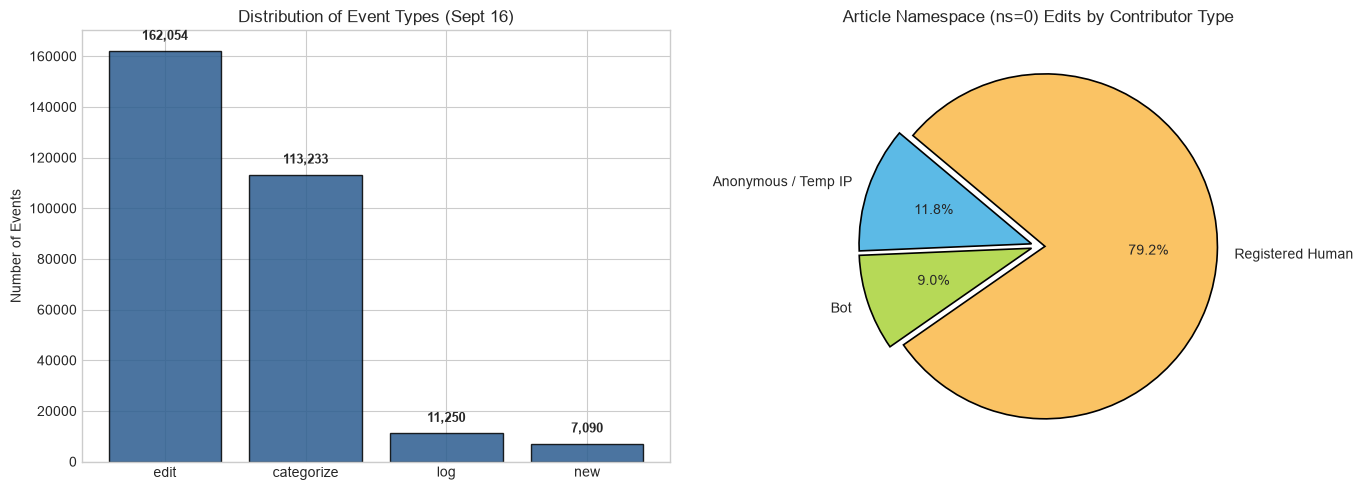

In [3]:
# Aggregation 1: Breakdown by MediaWiki event type
types_df = rc.groupBy("type").count().orderBy(F.desc("count")).toPandas()

# Aggregation 2: Editor classification for main namespace articles (ns = 0)
editor_split = (rc.filter("ns = 0 AND type IN ('edit', 'new')")
                  .select(F.when(F.col("bot"), "Bot")
                           .when(F.col("is_anon"), "Anonymous / Temp IP")
                           .otherwise("Registered Human").alias("editor_class"))
                  .groupBy("editor_class").count().toPandas())

# Visual comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.bar(types_df["type"], types_df["count"], color="#2b5c8f", edgecolor="black", alpha=0.85)
ax1.set_title("Distribution of Event Types (Sept 16)")
ax1.set_ylabel("Number of Events")
for i, v in enumerate(types_df["count"]):
    ax1.text(i, v + total_changes * 0.015, f"{v:,}", ha="center", fontsize=9, fontweight="bold")

n_classes = len(editor_split)
palette = ["#5cbae6", "#b6d957", "#fac364", "#f27979"]
ax2.pie(editor_split["count"], labels=editor_split["editor_class"], autopct="%1.1f%%",
        startangle=140, colors=palette[:n_classes], explode=[0.04] * n_classes,
        wedgeprops=dict(edgecolor="black", linewidth=1.2))
ax2.set_title("Article Namespace (ns=0) Edits by Contributor Type")
plt.tight_layout()
plt.show()

---
## Section 3: Hourly Edit Velocity & Revert Pulse

### Analytical Value
Wikipedia edits follow a global diurnal rhythm driven by active time zones across the Americas, Europe, and Asia.
- The primary axis tracks **Total Article Edits**, separated into **Human Edits** vs **Bot Edits**.
- The secondary axis tracks **Reverts per Hour**. Sudden surges in reverts signal widespread misinformation outbreaks, vandalism spikes, or high-profile edit wars.

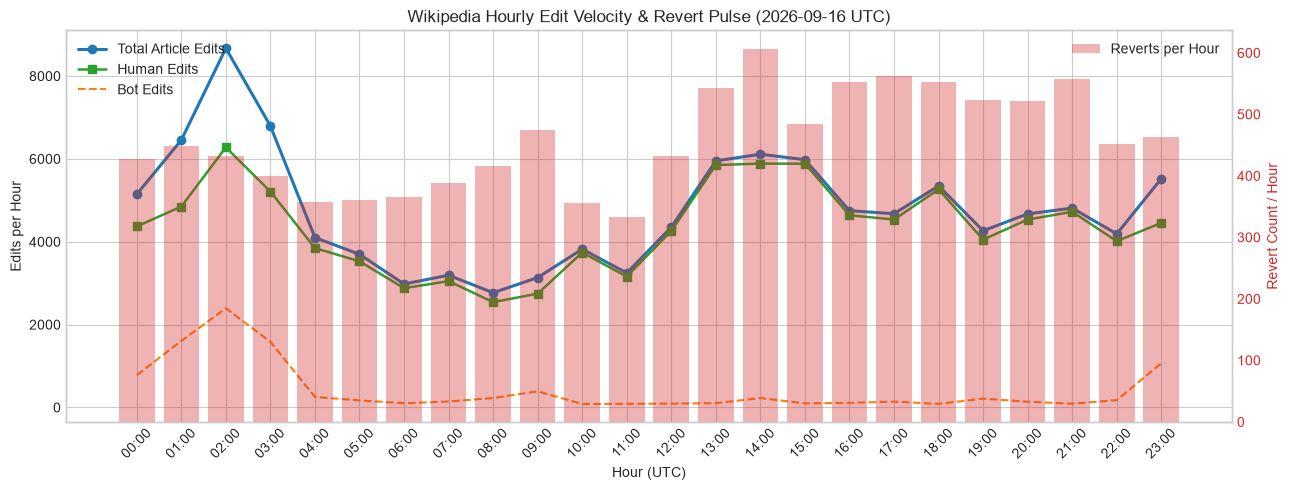

In [4]:
hourly = (rc.filter("ns = 0 AND type IN ('edit','new')")
   .groupBy("hour").agg(
        F.count("*").alias("total_edits"),
        F.sum(F.when(~F.col("bot"), 1).otherwise(0)).alias("human_edits"),
        F.sum(F.col("bot").cast("int")).alias("bot_edits"),
        F.sum(F.col("is_revert").cast("int")).alias("reverts"))
   .orderBy("hour")).toPandas()

hourly["hour_str"] = pd.to_datetime(hourly["hour"]).dt.strftime("%H:00")

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.plot(hourly["hour_str"], hourly["total_edits"], label="Total Article Edits", marker="o", color="#1f77b4", lw=2.2)
ax1.plot(hourly["hour_str"], hourly["human_edits"], label="Human Edits", marker="s", color="#2ca02c", lw=1.8)
ax1.plot(hourly["hour_str"], hourly["bot_edits"], label="Bot Edits", linestyle="--", color="#ff7f0e", lw=1.5)
ax1.set_xlabel("Hour (UTC)")
ax1.set_ylabel("Edits per Hour")
ax1.set_title("Wikipedia Hourly Edit Velocity & Revert Pulse (2026-09-16 UTC)")
ax1.tick_params(axis="x", rotation=45)
ax1.legend(loc="upper left")

# Secondary axis for revert frequency
ax2 = ax1.twinx()
ax2.bar(hourly["hour_str"], hourly["reverts"], alpha=0.35, color="#d62728", label="Reverts per Hour")
ax2.set_ylabel("Revert Count / Hour", color="#d62728")
ax2.tick_params(axis="y", labelcolor="#d62728")
ax2.grid(False)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

---
## Section 4: Top 15 Hottest Wikipedia Articles

### Identifying Attention vs Single-Editor Revamps
A page with 100 edits made by 1 single person is a **routine document revamp** (e.g., cataloging flora, expanding filmography).
Conversely, a page with 100 edits made by 25 distinct individuals indicates a **breaking news event or real-time developing topic**.

Here, we aggregate non-bot edits in `ns = 0`, plotting **Total Human Edits (Bars)** alongside **Distinct Editors (Orange Points)**.

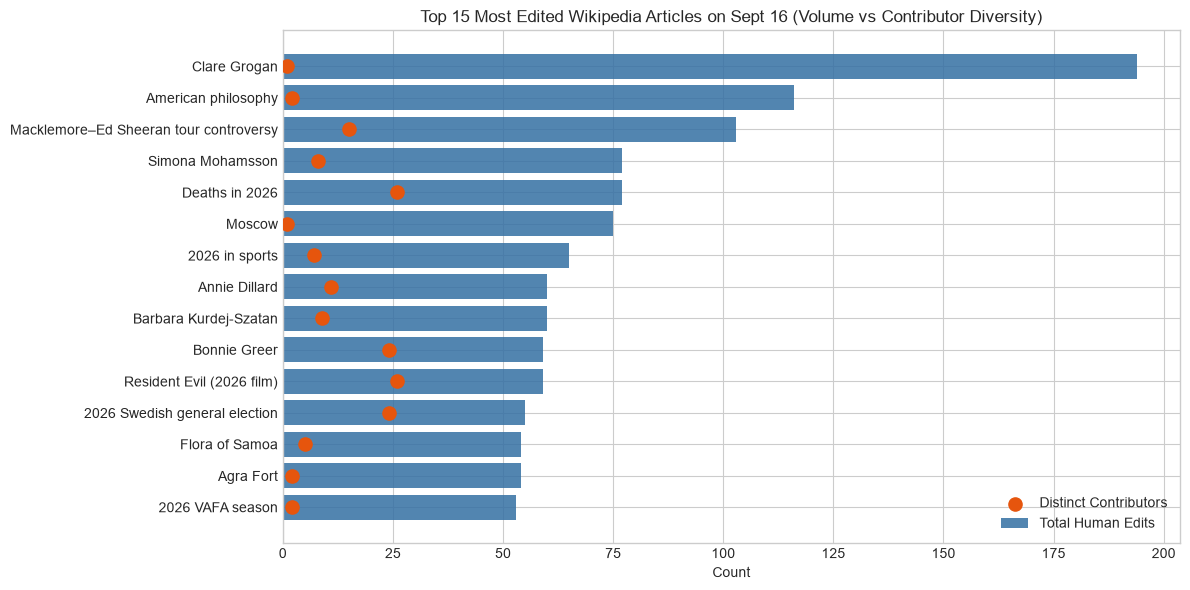

In [5]:
hot = (rc.filter("ns = 0 AND NOT bot")
         .groupBy("pageid", "title").agg(
             F.count("*").alias("edits"),
             F.countDistinct("user").alias("editors"),
             F.sum(F.col("is_revert").cast("int")).alias("reverts"),
             F.sum(F.abs("delta")).alias("bytes_churn"))
         .withColumn("revert_ratio", F.round(F.col("reverts") / F.col("edits"), 3)))

top_hot = hot.orderBy(F.desc("edits")).limit(15).toPandas()

plt.figure(figsize=(12, 6))
plt.barh(top_hot["title"][::-1], top_hot["edits"][::-1], color="#3470a3", label="Total Human Edits", alpha=0.85)
plt.scatter(top_hot["editors"][::-1], top_hot["title"][::-1], color="#e6550d", s=90, zorder=5, label="Distinct Contributors")
plt.xlabel("Count")
plt.title("Top 15 Most Edited Wikipedia Articles on Sept 16 (Volume vs Contributor Diversity)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

---
## Section 5: Algorithmic Controversy & Edit War Scoring

### Project-WikiPulse Metric Formula
To detect contentious topics algorithmically without relying on manual reporting, we formulate the **WikiPulse Controversy Metric**:

$$\text{Controversy Score} = \ln(1 + \text{edits}) \times \ln(1 + \text{editors}) \times (\text{revert\_ratio} + 0.05)$$

**Why this formula?**
1. **Volume Dampening ($\ln(1+\text{edits})$)**: Prevents high-volume pages from dominating without active disagreement.
2. **Breadth Factor ($\ln(1+\text{editors})$)**: Distinguishes multi-user disputes from one user repeatedly undoing an automated bot.
3. **Volatility Multiplier ($\text{revert\_ratio}$)**: Directly scales with the percentage of edits that were reverted or undone.
4. **Minimum Threshold ($\text{edits} \ge 15$)**: Eliminates small stub pages where 1 revert out of 1 edit creates an artificial 100% revert ratio.

In the bubble chart below:
- **X-Axis**: Total Edits
- **Y-Axis**: Revert Count
- **Bubble Size**: Computed Controversy Score
- **Bubble Color**: Revert Ratio

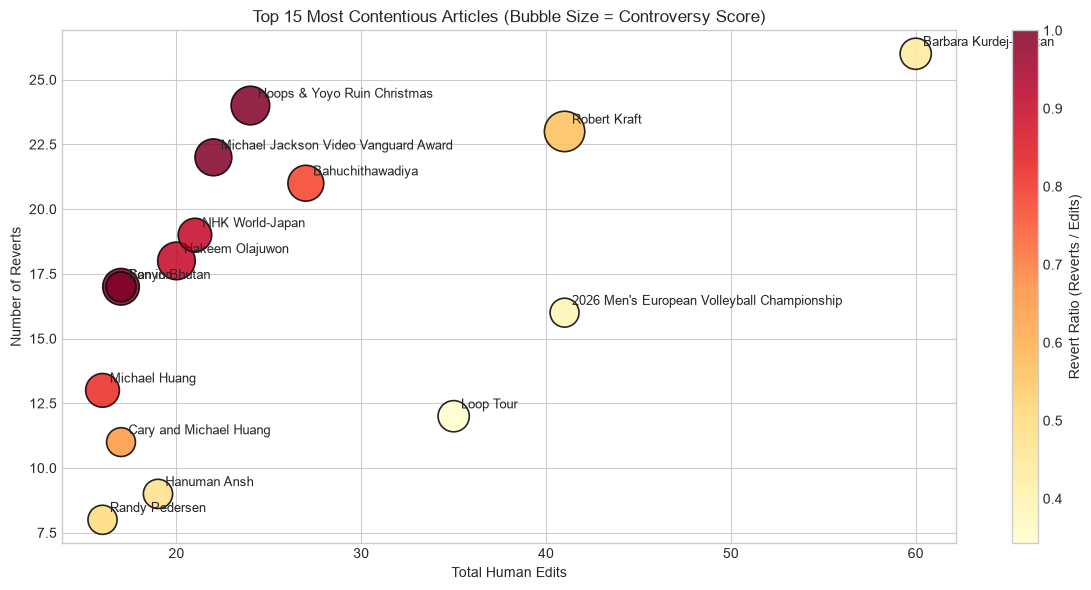

In [6]:
controversial = (hot.filter("edits >= 15")
                    .withColumn("controversy", F.round(
                        F.log1p("edits") * F.log1p("editors") * (F.col("revert_ratio") + 0.05), 3))
                    .orderBy(F.desc("controversy"))
                    .limit(15).toPandas())

fig, ax = plt.subplots(figsize=(12, 6))
scatter = ax.scatter(controversial["edits"], controversial["reverts"], 
                     s=controversial["controversy"] * 110, 
                     c=controversial["revert_ratio"], cmap="YlOrRd", 
                     alpha=0.85, edgecolors="black", linewidth=1.2)

# Label each article bubble
for _, row in controversial.iterrows():
    ax.annotate(row["title"], (row["edits"] + 0.4, row["reverts"] + 0.3), fontsize=9)

cbar = plt.colorbar(scatter)
cbar.set_label("Revert Ratio (Reverts / Edits)")
ax.set_xlabel("Total Human Edits")
ax.set_ylabel("Number of Reverts")
ax.set_title("Top 15 Most Contentious Articles (Bubble Size = Controversy Score)")
plt.tight_layout()
plt.show()

---
## Section 6: Information Volatility (Gross Byte Churn Leaders)

### Net Delta vs Gross Churn
- **Net Delta** ($|\text{final length} - \text{initial length}|$): Often hides edit wars because repeatedly adding 1,000 bytes and deleting 1,000 bytes produces 0 net change.
- **Gross Churn** ($\sum |\Delta| = \sum |\text{newlen} - \text{oldlen}|$): Accurately tracks information churn and instability.

Pages with hundreds of kilobytes of churn in 24 hours reflect either wholesale page rewrites or severe multi-party revert loops.

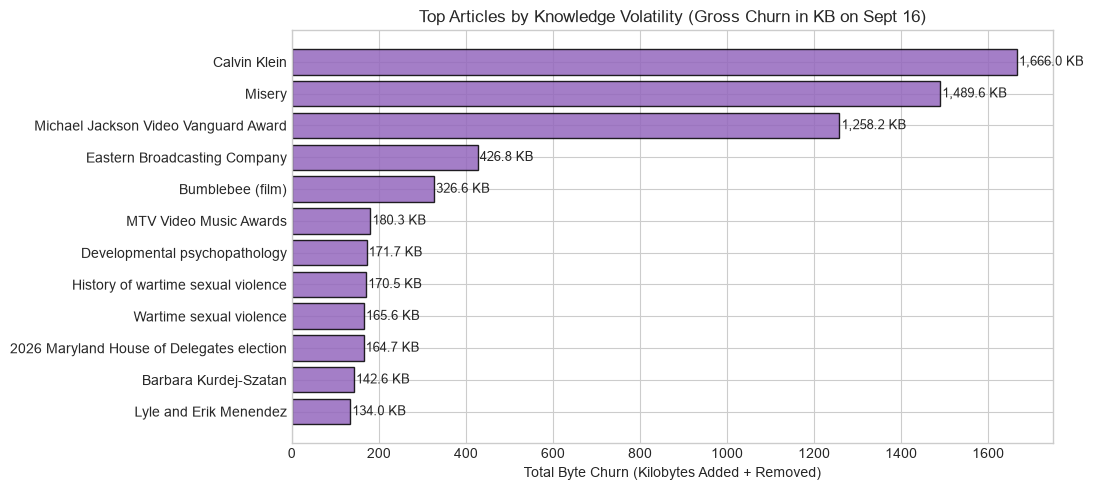

In [7]:
churn = hot.orderBy(F.desc("bytes_churn")).limit(12).toPandas()
churn["kb_churn"] = churn["bytes_churn"] / 1024.0

plt.figure(figsize=(11, 5))
bars = plt.barh(churn["title"][::-1], churn["kb_churn"][::-1], color="#9467bd", edgecolor="black", alpha=0.85)
plt.xlabel("Total Byte Churn (Kilobytes Added + Removed)")
plt.title("Top Articles by Knowledge Volatility (Gross Churn in KB on Sept 16)")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 5, bar.get_y() + bar.get_height()/2, f"{w:,.1f} KB", va="center", fontsize=9)
plt.tight_layout()
plt.show()

---
## Section 7: Contribution Channels & Editing Interfaces

### Tracking Platform Shifts
MediaWiki tags record which client tool or workflow submitted each change:
- `wikieditor`: Traditional desktop wikitext editor.
- `mobile edit` / `mobile web edit` / `mobile app edit`: Smartphone edits.
- `visualeditor`: What-You-See-Is-What-You-Get (WYSIWYG) web interface.
- `AWB` (AutoWikiBrowser) & `JWB`: Semi-automated script tools operated by trusted editors.
- `mw-reverted` / `mw-undo`: System tags applied to rollback and revert actions.

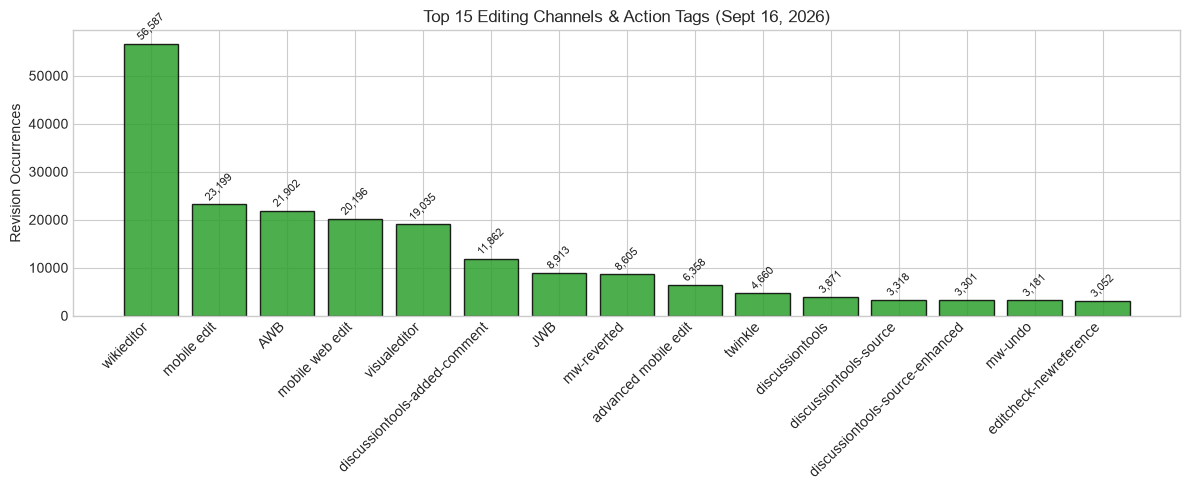

In [8]:
tags_df = (rc.select(F.explode("tags").alias("tag"))
             .groupBy("tag").count()
             .orderBy(F.desc("count"))
             .limit(15).toPandas()
             .dropna())

plt.figure(figsize=(12, 5))
plt.bar(tags_df["tag"], tags_df["count"], color="#2ca02c", edgecolor="black", alpha=0.85)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Revision Occurrences")
plt.title("Top 15 Editing Channels & Action Tags (Sept 16, 2026)")
for i, v in enumerate(tags_df["count"]):
    plt.text(i, v + 800, f"{v:,}", ha="center", fontsize=8, rotation=45)
plt.tight_layout()
plt.show()

---
## Section 8: Curated Parquet Data Lake Export

### Downstream Integration
We persist our aggregated metrics (`edits`, `editors`, `reverts`, `bytes_churn`, `revert_ratio`) into **Apache Parquet** format.
- Parquet provides columnar compression, dictionary encoding, and instant partition pruning.
- Downstream BI tools, ML pipelines, and real-time dashboard servers can read this directly without reprocessing gigabytes of raw JSONL.

In [9]:
output_parquet_path = "data/curated/hot_pages_2026-09-16"
hot.write.mode("overwrite").parquet(output_parquet_path)
print(f"✓ Curated Parquet dataset successfully written to: {output_parquet_path}")

✓ Curated Parquet dataset successfully written to: data/curated/hot_pages_2026-09-16


### Conclusion & Next Steps in WikiPulse
1. **Multi-Day Longitudinal Trends**: As historical collector runs finish downloading the entire month (Sept 16 – Oct 15), the same pipeline can run across all days (`rc_*.jsonl.gz`) to observe longitudinal lifecycle patterns.
2. **Cross-API Join with Pageviews**: Ingest `data/analytics/pageviews_top_daily.json` into Spark to correlate attention spikes with edit wars (identifying which breaking events drive reader traffic vs internal editor contention).
3. **Streaming Replay**: Feed these batch findings into Kafka / Spark Structured Streaming for real-time alerting on emerging controversies.

In [10]:
# To release JVM executor memory when completely finished, uncomment below:
# spark.stop()
print("WikiPulse Spark Analysis Complete!")

WikiPulse Spark Analysis Complete!
